In [5]:
# setup
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
FIGURES = PROJECT_ROOT / 'results/figures'
RAW = PROJECT_ROOT / 'data/raw'
PROCESSED = PROJECT_ROOT / 'data/processed'

In [6]:
#doc du lieu
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_excel(RAW / "default of credit card clients.xls",
    header=1)
print("Kich co du lieu: ", df.shape)
display(df.head(5))

C:\Users\FPT SHOP\AppData\Local\Temp\ipykernel_3792\2352877173.py:9: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(RAW / "default of credit card clients.xls",


Kich co du lieu:  (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [7]:
#khao sat, chuan hoa du lieu
print("Thong tin du lieu: ")
df.info()

print("\nSo luong gia tri thieu:")
print(df.isnull().sum())

print("So dong trung: ", df.duplicated().sum())

print("\nThong ke mo ta: ")
print(df.describe())

print("Ten cot trc khi chuan hoa: ", df.columns)
print(df.columns.tolist())

df.columns = [str(c) for c in df.columns]
print("Ten cot sau khi xoa khoang trang: ", df.columns.tolist())

rename_map = {
    'default payment next month': 'default_next_month',
    "Y": "default_next_month",
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",

    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",

    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",

    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6"
}
df = df.rename(columns=rename_map)
print("Ten cot sau khi chuan hoa: ", df.columns.tolist())

if "default_next_month" in df.columns:
    candidates=[c for c in df.columns if "default" in c.lower() or c.lower()=="Y"]
    if candidates:
        df=df.rename(columns={candidates[-1]:"default_next_month"})
df = df.rename(columns={'PAY_0':'PAY_1'})
if "default_next_month" not in df.columns:
    raise ValueError("Không tìm thấy cột nhãn. Hãy kiểm tra tên cột của file dữ liệu.")

print("Kích thước dữ liệu:", df.shape)
display(df.head())


Thong tin du lieu: 
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 1

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [23]:
# LÀM SẠCH DỮ LIỆU
import json
from pathlib import Path

n_raw = len(df)

# 1. Bỏ cột ID (phải bỏ TRƯỚC khi kiểm tra trùng)
if "ID" in df.columns:
    df = df.drop(columns="ID")

# 2. Loại dòng trùng lặp hoàn toàn
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(f"Đã loại {n_dup} dòng trùng; còn {len(df)} dòng")

# 3. Giá trị thiếu (bộ dữ liệu không có)
assert df.isna().sum().sum() == 0, "Có giá trị thiếu!"

# 4. Gộp mã không được mô tả vào nhóm "khác"
for col, mapping in {"EDUCATION": {0: 4, 5: 4, 6: 4}, "MARRIAGE": {0: 3}}.items():
    pct = df[col].isin(mapping.keys()).mean() * 100
    print(f"{col}: {pct:.2f}% dòng được gộp (kỳ vọng < 2%)")
    df[col] = df[col].replace(mapping)

# 5. Ghi run_log.json
Path("../results").mkdir(parents=True, exist_ok=True)
with open("../results/run_log.json", "w", encoding="utf-8") as f:
    json.dump({"n_rows_raw": n_raw,
               "n_duplicates_removed": n_dup,
               "n_rows_clean": len(df)}, f, ensure_ascii=False, indent=2)

# PAY_1..PAY_6 giữ dạng số có thứ tự; BILL_AMT giữ giá trị âm; không cắt ngoại lai


Đã loại 35 dòng trùng; còn 29965 dòng
EDUCATION: 1.15% dòng được gộp (kỳ vọng < 2%)
MARRIAGE: 0.18% dòng được gộp (kỳ vọng < 2%)


In [9]:
#cau truc & chat luong du lieu
print("So dong: ", df.shape[0])
print("So cot: ", df.shape[1])
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_inunique": df.nunique()
}).sort_values(by="missing_pct", ascending=False))
print("So dong trung hoan toan: ", df.duplicated().sum())
if "ID" in df.columns:
    print("ID duy nhat: ", df["ID"].nunique(), "/", len(df))

So dong:  30000
So cot:  25


,dtype,missing_count,missing_pct,n_inunique
ID,int64,0,0.0,30000
LIMIT_BAL,int64,0,0.0,81
SEX,int64,0,0.0,2
EDUCATION,int64,0,0.0,7
MARRIAGE,int64,0,0.0,4
AGE,int64,0,0.0,56
PAY_1,int64,0,0.0,11
PAY_2,int64,0,0.0,11
PAY_3,int64,0,0.0,11
PAY_4,int64,0,0.0,11


So dong trung hoan toan:  0
ID duy nhat:  30000 / 30000


In [10]:
#thong ke mo ta
display(df.describe(include="all").T)

# thong ke rieng cho cac nhom bien chinh
pay_cols = [c for c in ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] if c in df.columns]
bill_cols = [c for c in df.columns if c.startswith("BILL_AMT")]
payment_cols = [c for c in df.columns if c.startswith("PAY_AMT")]
amount_cols = [c for c in ["LIMIT_BAL", "AGE"] + bill_cols + payment_cols if c in df.columns]

if amount_cols:
    display(df[amount_cols].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,10000.00,50000.00,140000.0,240000.00,430000.00,500000.00,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,22.00,28.00,34.0,41.00,53.00,60.00,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,-81.00,3558.75,22381.5,67091.00,201203.05,350110.68,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,-200.00,2984.75,21200.0,64006.25,194792.20,337495.28,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,-200.00,2666.25,20088.5,60164.75,187821.05,325030.39,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,-212.02,2326.75,19052.0,54506.00,174333.35,304997.27,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,-232.01,1763.00,18104.5,50190.50,165794.30,285868.33,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,-331.03,1256.00,17071.0,49198.25,161912.00,279505.06,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,0.00,1000.00,2100.0,5006.00,18428.20,66522.18,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,0.00,833.00,2009.0,5000.00,19004.35,76651.02,1684259.0


In [11]:
#bien phan loai/thu tu bang tan suat
for c in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{c}"); display(df[c].value_counts().sort_index().to_frame("so_khach_hang").assign(ty_le_pct=lambda x: (x.so_khach_hang / len(df) * 100).round(2)).T)
print("\nPAY_1 (trạng thái thanh toán tháng gần nhất)")
display(df["PAY_1"].value_counts().sort_index().to_frame("so_khach_hang").T)


SEX


SEX,1,2
so_khach_hang,11888.00,18112.00
ty_le_pct,39.63,60.37



EDUCATION


EDUCATION,0,1,2,3,4,5,6
so_khach_hang,14.00,10585.00,14030.00,4917.00,123.00,280.00,51.00
ty_le_pct,0.05,35.28,46.77,16.39,0.41,0.93,0.17



MARRIAGE


MARRIAGE,0,1,2,3
so_khach_hang,54.00,13659.00,15964.00,323.00
ty_le_pct,0.18,45.53,53.21,1.08



PAY_1 (trạng thái thanh toán tháng gần nhất)


PAY_1,-2,-1,0,1,2,3,4,5,6,7,8
so_khach_hang,2759,5686,14737,3688,2667,322,76,26,11,9,19


,count,percent
default_next_month,,
0,23364,77.88
1,6636,22.12


Tỷ lệ vỡ nợ (nhãn 1): 22.12%


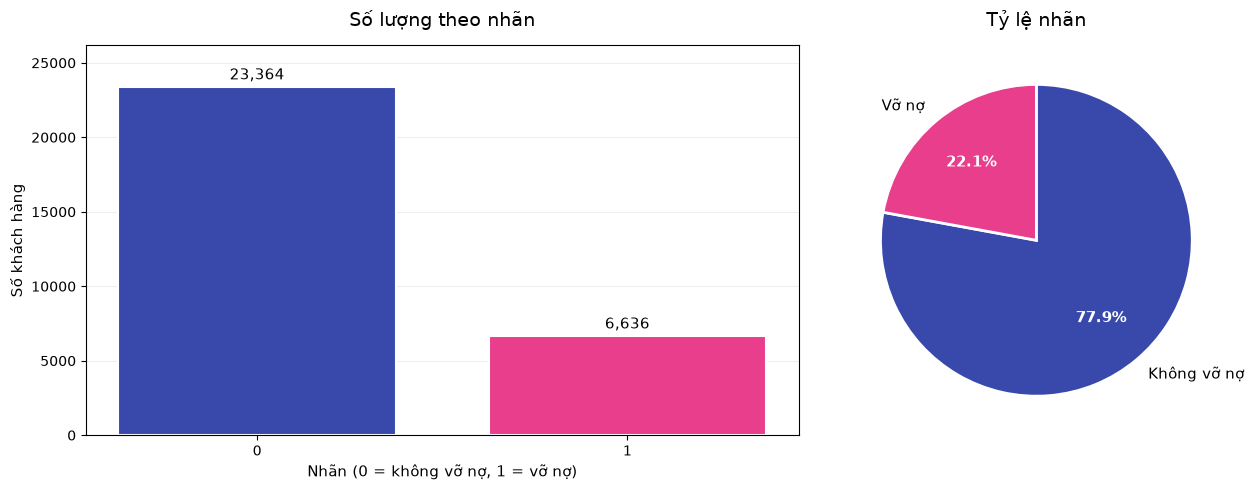

In [12]:


# Tên cột mục tiêu
target = "default_next_month"

# Thống kê nhãn 0 và 1
target_counts = (
    df[target]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

target_pct = target_counts / target_counts.sum() * 100

display(pd.DataFrame({
    "count": target_counts,
    "percent": target_pct.round(2)
}))

print(
    f"Tỷ lệ vỡ nợ (nhãn 1): "
    f"{target_pct.loc[1]:.2f}%"
)

# Bảng màu theo hình bạn gửi
blue = "#3949AB"       # Xanh dương
pink = "#E83E8C"       # Hồng


colors = [blue, pink]
background = "#FFFFFF"

# Tạo thư mục lưu biểu đồ
# os.makedirs("figures", exist_ok=True)

# Tạo 2 biểu đồ cạnh nhau
fig, ax = plt.subplots(
    1, 2,
    figsize=(13, 5),
    gridspec_kw={"width_ratios": [1.6, 1]}
)

fig.patch.set_facecolor(background)

# =========================
# 1. Biểu đồ cột
# =========================
bars = ax[0].bar(
    [str(i) for i in target_counts.index],
    target_counts.values,
    color=colors,
    width=0.75,
    edgecolor="white",
    linewidth=1.5
)

ax[0].set_title(
    "Số lượng theo nhãn",
    fontsize=14,
    pad=14
)
ax[0].set_xlabel(
    "Nhãn (0 = không vỡ nợ, 1 = vỡ nợ)",
    fontsize=11
)
ax[0].set_ylabel("Số khách hàng", fontsize=11)

ax[0].set_facecolor(background)
ax[0].grid(axis="y", alpha=0.2)
ax[0].set_axisbelow(True)

# Hiển thị số lượng trên đầu cột
ax[0].bar_label(
    bars,
    labels=[f"{int(v):,}" for v in target_counts.values],
    padding=3,
    fontsize=11
)

ax[0].set_ylim(0, max(target_counts.max() * 1.12, 1))

# =========================
# 2. Biểu đồ tròn
# =========================
wedges, texts, autotexts = ax[1].pie(
    target_counts.values,
    labels=["Không vỡ nợ", "Vỡ nợ"],
    autopct="%1.1f%%",
    colors=colors,
    startangle=90,
    counterclock=False,
    pctdistance=0.65,
    labeldistance=1.12,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={"fontsize": 11}
)

for text in autotexts:
    text.set_fontsize(11)
    text.set_color("white")
    text.set_fontweight("bold")

ax[1].set_title(
    "Tỷ lệ nhãn",
    fontsize=14,
    pad=14
)

# Lưu và hiển thị
plt.tight_layout()

plt.savefig(
    FIGURES / "01_label_distribution.png",
    dpi=200,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


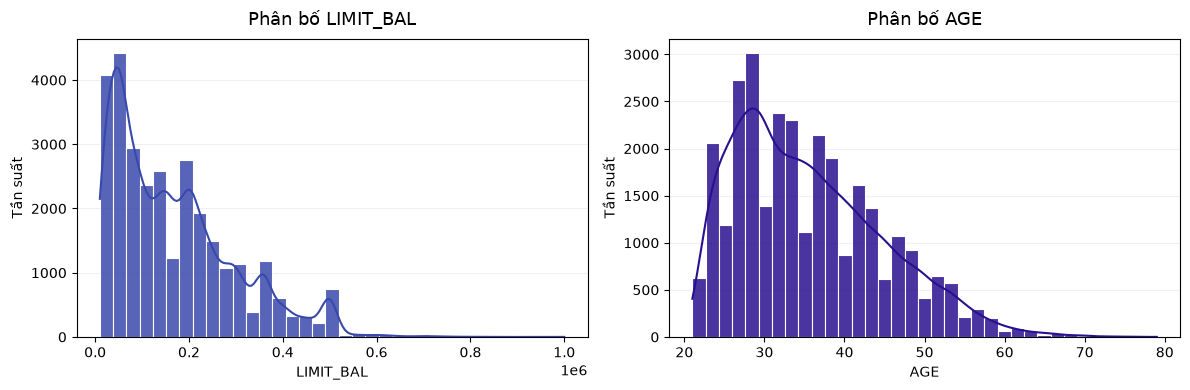

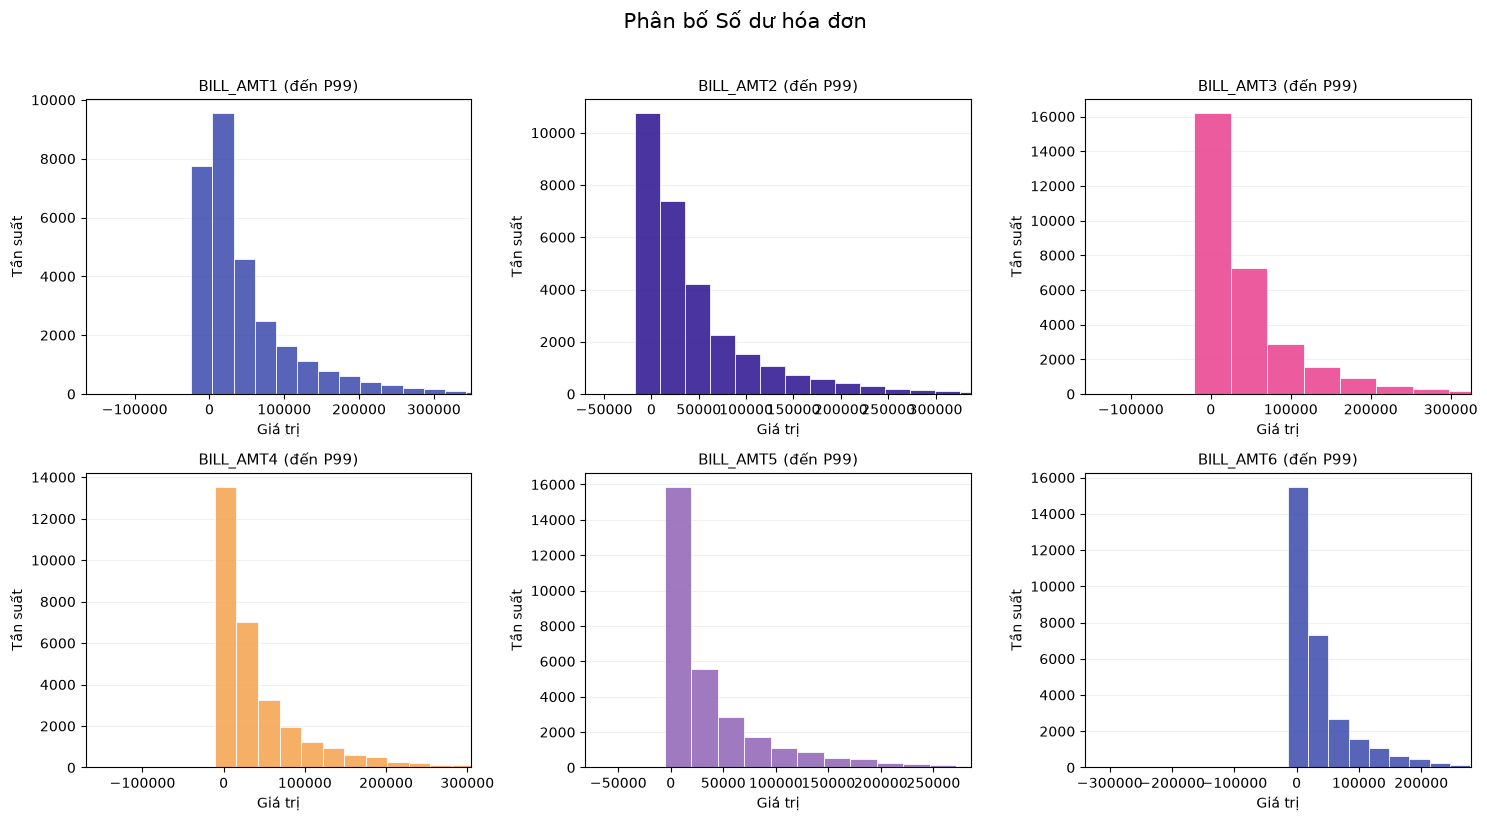

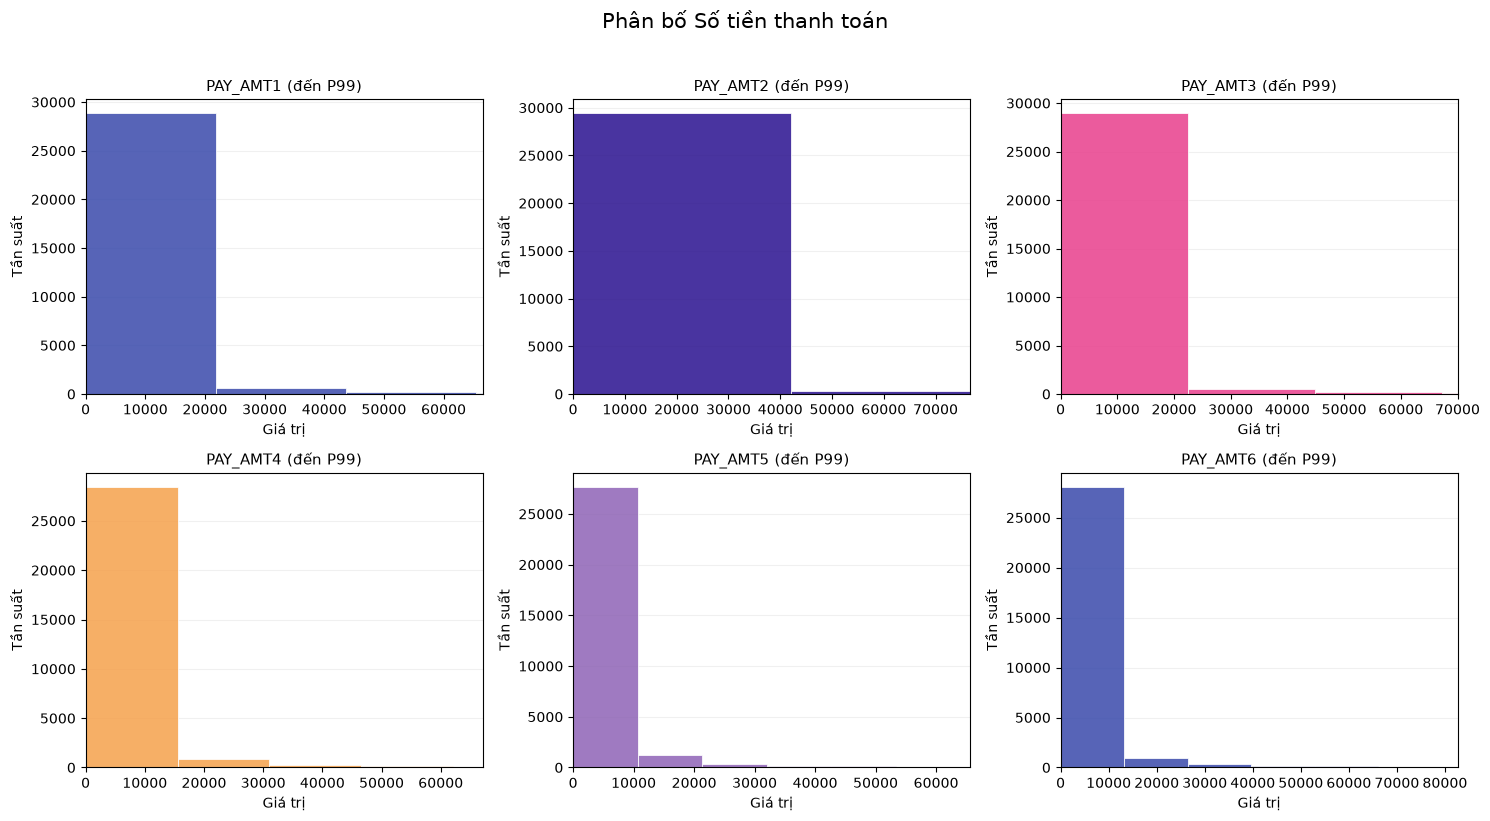

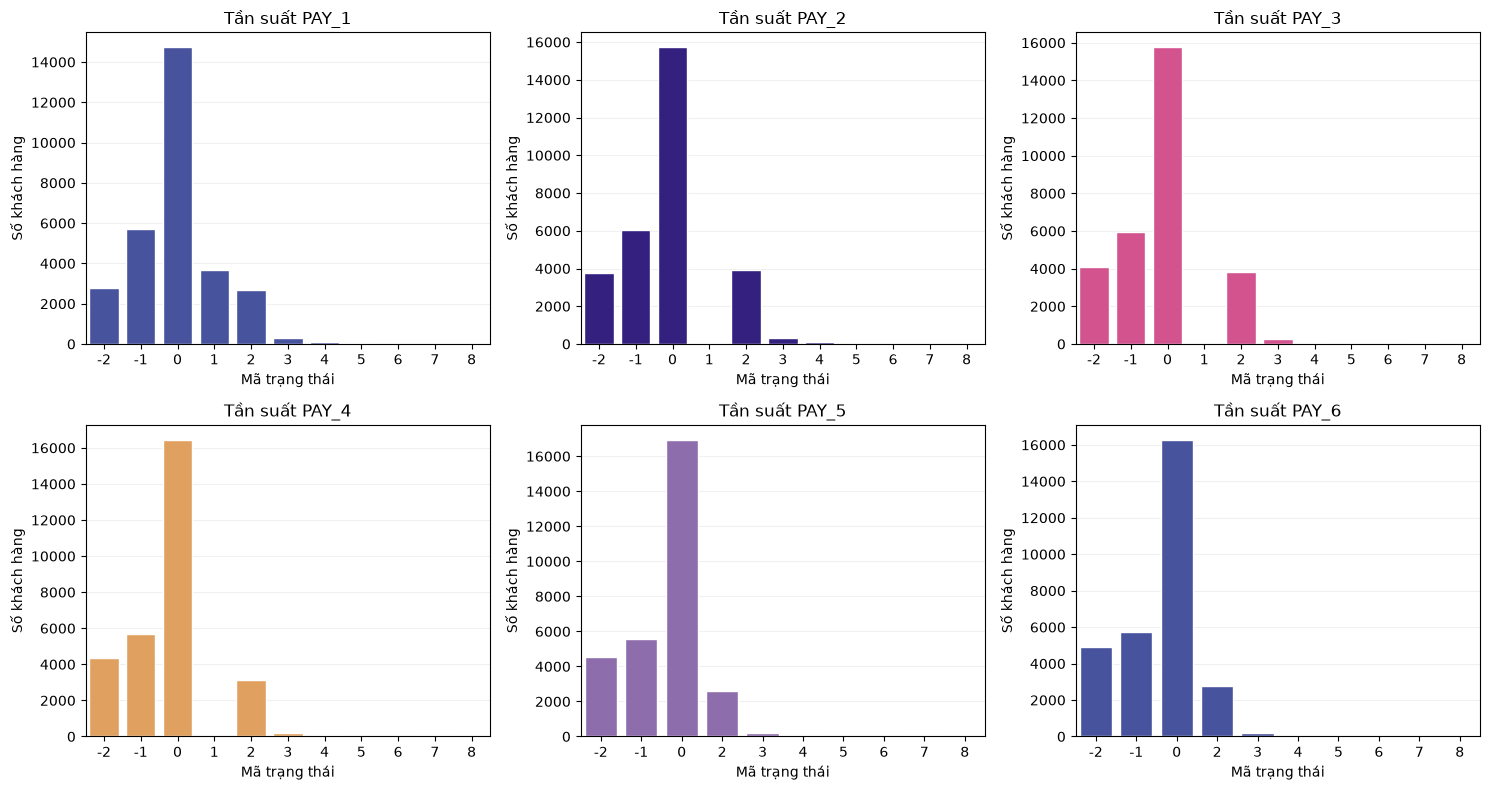

In [13]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
pay_cols = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

# Hạn mức tín dụng và tuổi
import matplotlib.pyplot as plt
import seaborn as sns

# Bảng màu pastel đậm
blue = "#3949AB"       # Xanh dương
purple = "#29108F"     # Tím đậm
pink = "#E83E8C"       # Hồng
orange = "#F5A14B"     # Cam
lavender = "#8E63B6"   # Tím nhạt

palette = [blue, purple, pink, orange, lavender]

# 1. Phân bố hạn mức tín dụng và tuổi
numeric_main = [
    c for c in ["LIMIT_BAL", "AGE"]
    if c in df.columns
]

if numeric_main:
    fig, axes = plt.subplots(
        1, len(numeric_main),
        figsize=(6 * len(numeric_main), 4)
    )

    if len(numeric_main) == 1:
        axes = [axes]

    for i, (col, ax) in enumerate(zip(numeric_main, axes)):
        sns.histplot(
            data=df,
            x=col,
            bins=35,
            kde=True,
            color=palette[i % len(palette)],
            edgecolor="white",
            alpha=0.85,
            ax=ax
        )

        ax.set_title(f"Phân bố {col}", fontsize=13, pad=10)
        ax.set_xlabel(col)
        ax.set_ylabel("Tần suất")
        ax.grid(axis="y", alpha=0.18)
        ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


# 2. Phân bố số dư hóa đơn và số tiền thanh toán
for group_name, cols in [
    ("Số dư hóa đơn", bill_cols),
    ("Số tiền thanh toán", payment_cols)
]:
    cols = [c for c in cols if c in df.columns]

    if cols:
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        axes = axes.flatten()

        for i, (col, ax) in enumerate(zip(cols, axes)):
            series = df[col].dropna()

            if series.empty:
                ax.set_visible(False)
                continue

            color = palette[i % len(palette)]

            sns.histplot(
                series,
                bins=40,
                color=color,
                edgecolor="white",
                alpha=0.85,
                ax=ax
            )

            q99 = series.quantile(0.99)
            lower = min(0, series.min())

            ax.set_xlim(
                left=lower,
                right=q99 if q99 > lower else None
            )

            ax.set_title(f"{col} (đến P99)", fontsize=11)
            ax.set_xlabel("Giá trị")
            ax.set_ylabel("Tần suất")
            ax.grid(axis="y", alpha=0.18)
            ax.set_axisbelow(True)

        for ax in axes[len(cols):]:
            ax.set_visible(False)

        fig.suptitle(
            f"Phân bố {group_name}",
            fontsize=15,
            y=1.02
        )

        plt.tight_layout()
        plt.savefig(
            '../results/figures/bill_distribution.png', 
            dpi=200,
            bbox_inches="tight",
            facecolor=fig.get_facecolor())
        plt.show()


# 3. Tần suất các trạng thái thanh toán
if pay_cols:
    valid_pay_cols = [c for c in pay_cols if c in df.columns]

    if valid_pay_cols:
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        axes = axes.flatten()

        for i, (col, ax) in enumerate(
            zip(valid_pay_cols, axes)
        ):
            order = sorted(df[col].dropna().unique())
            color = palette[i % len(palette)]

            sns.countplot(
                data=df,
                x=col,
                order=order,
                color=color,
                edgecolor="white",
                ax=ax
            )

            ax.set_title(f"Tần suất {col}", fontsize=12)
            ax.set_xlabel("Mã trạng thái")
            ax.set_ylabel("Số khách hàng")
            ax.grid(axis="y", alpha=0.18)
            ax.set_axisbelow(True)

        for ax in axes[len(valid_pay_cols):]:
            ax.set_visible(False)

        plt.tight_layout()
        plt.savefig(
            '../results/figures/pay_distribution.png',
            dpi=200,
            bbox_inches="tight",
            facecolor=fig.get_facecolor()
        )
        plt.show()


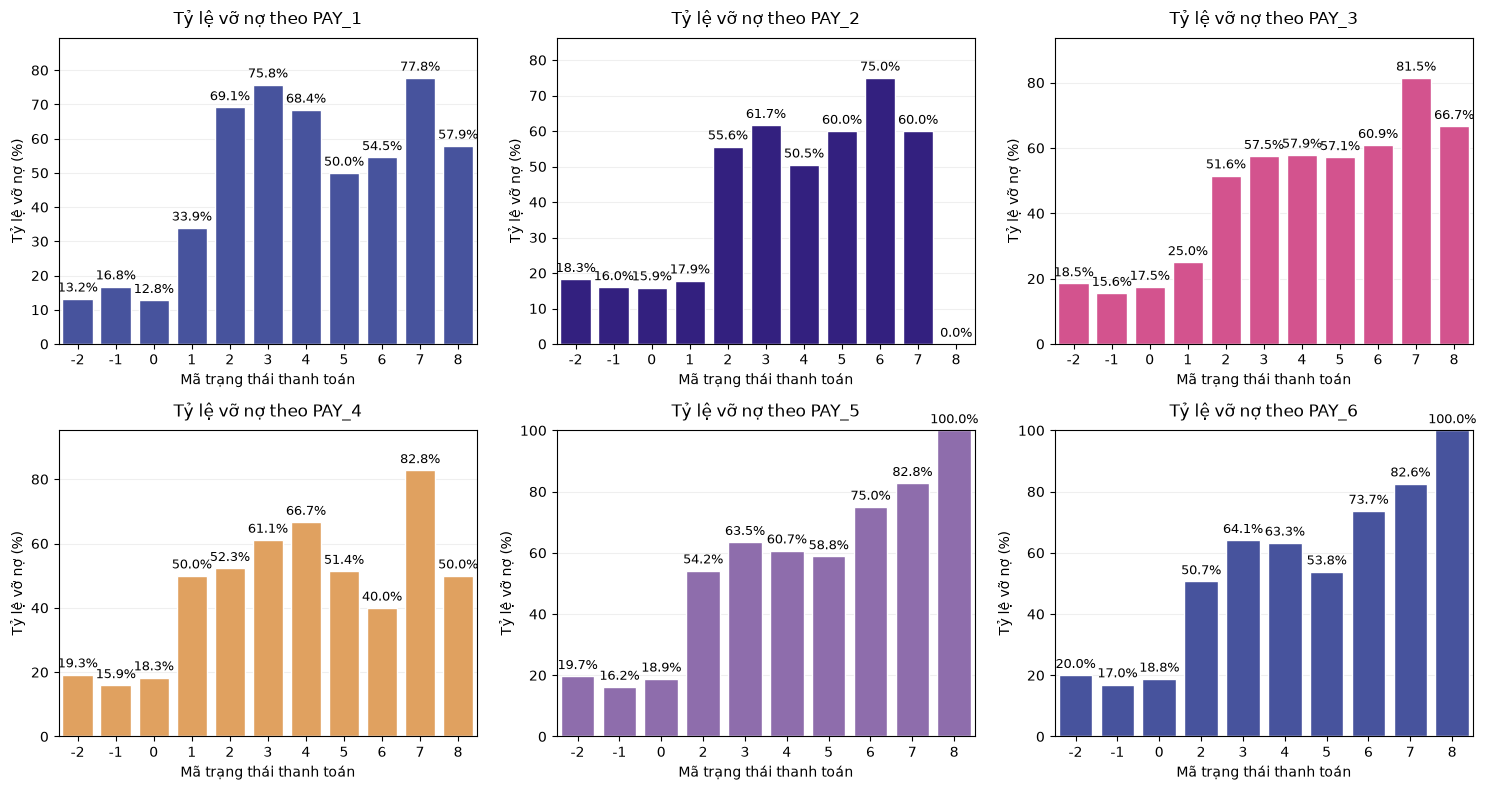

,so_khach_hang,ty_le_vo_no
PAY_1,,
-2,2759,13.23
-1,5686,16.78
0,14737,12.81
1,3688,33.95
2,2667,69.14
3,322,75.78
4,76,68.42
5,26,50.00
6,11,54.55


In [14]:

# QUAN HỆ GIỮA ĐẶC TRƯNG VÀ NHÃN
# Tỷ lệ vỡ nợ theo trạng thái thanh toán

# Kiểm tra các cột cần thiết
if target not in df.columns:
    raise KeyError(
        f"Không tìm thấy cột mục tiêu '{target}'. "
        f"Các cột hiện có: {df.columns.tolist()}"
    )

valid_pay_cols = [col for col in pay_cols if col in df.columns]

# Tỷ lệ vỡ nợ theo từng trạng thái thanh toán
if valid_pay_cols:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()

    for i, (col, ax) in enumerate(zip(valid_pay_cols, axes)):
        # Tính tỷ lệ vỡ nợ theo từng trạng thái
        rate = (
            df.groupby(col, observed=True)[target]
            .mean()
            .mul(100)
            .dropna()
        )

        plot_data = pd.DataFrame({
            "trang_thai": rate.index.astype(str),
            "ty_le_vo_no": rate.values
        })

        color = palette[i % len(palette)]

        sns.barplot(
            data=plot_data,
            x="trang_thai",
            y="ty_le_vo_no",
            color=color,
            edgecolor="white",
            ax=ax
        )

        # Hiển thị phần trăm trên đầu cột
        for container in ax.containers:
            ax.bar_label(
                container,
                fmt="%.1f%%",
                padding=3,
                fontsize=9
            )

        ax.set_title(
            f"Tỷ lệ vỡ nợ theo {col}",
            fontsize=12,
            pad=10
        )
        ax.set_xlabel("Mã trạng thái thanh toán")
        ax.set_ylabel("Tỷ lệ vỡ nợ (%)")
        ax.tick_params(axis="x", rotation=0)
        ax.set_ylim(0, min(100, max(rate.max() * 1.15, 5)))
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

    # Ẩn các ô biểu đồ không sử dụng
    for ax in axes[len(valid_pay_cols):]:
        ax.set_visible(False)

    fig.patch.set_facecolor("#FFFFFF")
    plt.tight_layout()
    plt.show()


# Bảng tỷ lệ vỡ nợ theo PAY_1
if "PAY_1" in df.columns:
    summary = (
        df.groupby("PAY_1")[target]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "so_khach_hang",
            "mean": "ty_le_vo_no"
        })
    )

    summary["ty_le_vo_no"] = (
        summary["ty_le_vo_no"] * 100
    ).round(2)

    display(summary)


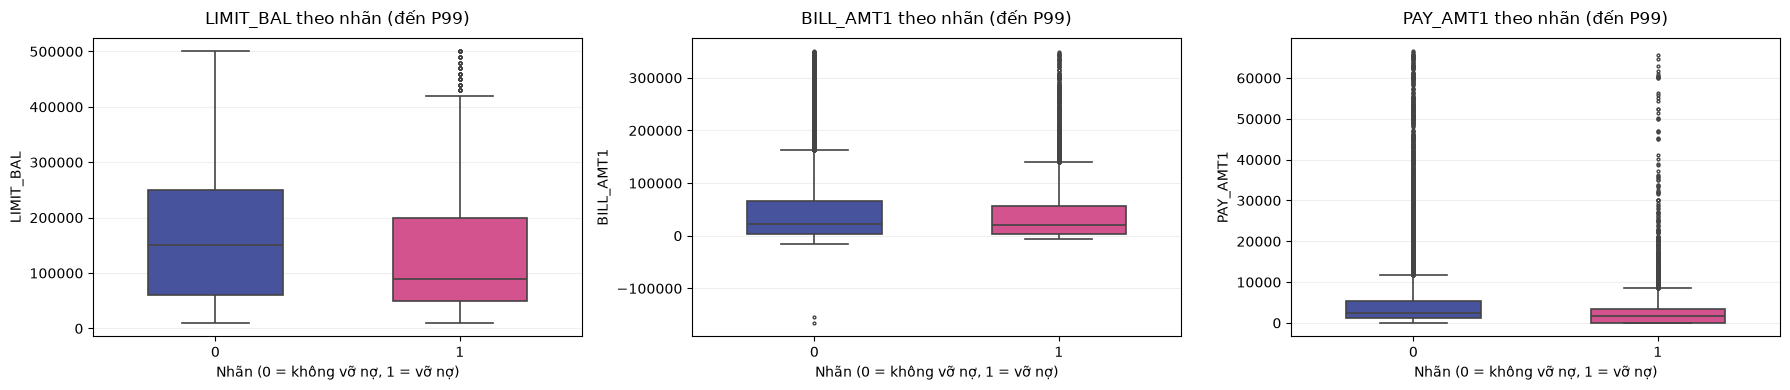

LIMIT_BAL               AGE        BILL_AMT1            \
                      median       mean median   mean    median      mean   
default_next_month                                                          
0                   150000.0  178099.73   34.0  35.42   23119.5  51994.23   
1                    90000.0  130109.66   34.0  35.73   20185.0  48509.16   

                   PAY_AMT1           
                     median     mean  
default_next_month                    
0                    2459.5  6307.34  
1                    1636.0  3397.04

In [15]:

# So sánh hạn mức tín dụng, hóa đơn và thanh toán theo nhãn
label_palette = {
    0: blue,
    1: pink
}

selected_amounts = [
    c for c in ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]
    if c in df.columns
]

if selected_amounts:
    fig, axes = plt.subplots(
        1,
        len(selected_amounts),
        figsize=(6 * len(selected_amounts), 4)
    )

    if len(selected_amounts) == 1:
        axes = [axes]

    for i, (col, ax) in enumerate(zip(selected_amounts, axes)):
        # Giới hạn hiển thị ở phân vị 99%, không sửa dữ liệu gốc
        cap = df[col].quantile(0.99)

        plot_df = df.loc[
            df[col] <= cap,
            [col, target]
        ].dropna().copy()

        sns.boxplot(
            data=plot_df,
            x=target,
            y=col,
            hue=target,
            order=[0, 1],
            hue_order=[0, 1],
            palette=label_palette,
            legend=False,
            width=0.55,
            linewidth=1.2,
            fliersize=2,
            ax=ax
        )

        ax.set_title(
            f"{col} theo nhãn (đến P99)",
            fontsize=12,
            pad=10
        )
        ax.set_xlabel("Nhãn (0 = không vỡ nợ, 1 = vỡ nợ)")
        ax.set_ylabel(col)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

    fig.patch.set_facecolor("#FFFFFF")
    plt.tight_layout()
    plt.show()


# Tóm tắt thống kê theo nhãn
summary_cols = [
    c for c in ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
    if c in df.columns
]

display(
    df.groupby(target)[summary_cols]
    .agg(["median", "mean"])
    .round(2)
)


,so_khach_hang,ty_le_vo_no_pct
nhom,,
Nam,11874,24.16
Nữ,18091,20.79


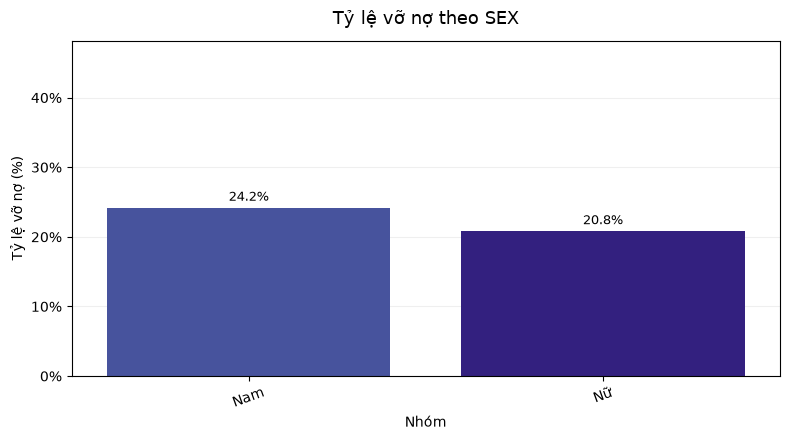

,so_khach_hang,ty_le_vo_no_pct
nhom,,
THPT,4915,25.17
Đại học,14019,23.74
Sau đại học,10563,19.24
Khác,468,7.05


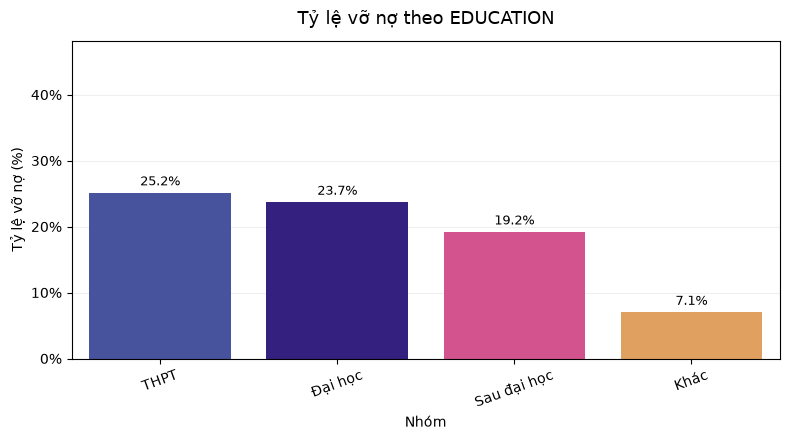

,so_khach_hang,ty_le_vo_no_pct
nhom,,
Khác,377,23.61
Đã kết hôn,13643,23.46
Độc thân,15945,20.95


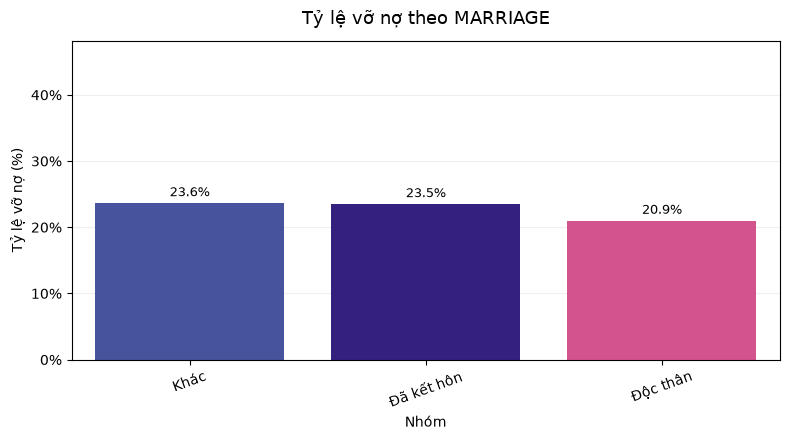

,so_khach_hang,ty_le_vo_no_pct
age_group,,
≤25,3868,26.65
26–35,12919,19.85
36–45,8512,21.80
46–55,3822,24.96
56–65,758,26.52
>65,86,26.74


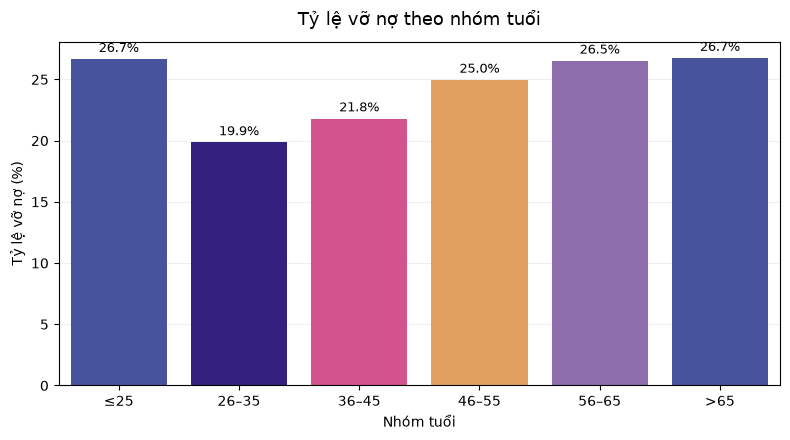

In [24]:

# MỐI QUAN HỆ GIỮA ĐẶC TRƯNG DANH MỤC, TUỔI VÀ NHÃN
background = "#FFFFFF"

# Mã danh mục theo mô tả dữ liệu UCI
category_maps = {
    "SEX": {
        1: "Nam",
        2: "Nữ"
    },
    "EDUCATION": {
        1: "Sau đại học",
        2: "Đại học",
        3: "THPT",
        4: "Khác",
        5: "Không rõ (5)",
        6: "Không rõ (6)",
        0: "Không rõ (0)"
    },
    "MARRIAGE": {
        1: "Đã kết hôn",
        2: "Độc thân",
        3: "Khác",
        0: "Không rõ (0)"
    }
}

# Kiểm tra cột mục tiêu
if target not in df.columns:
    raise KeyError(
        f"Không tìm thấy cột '{target}'. "
        f"Các cột hiện có: {df.columns.tolist()}"
    )

# 1. Tỷ lệ vỡ nợ theo các biến danh mục
for i, (col, mapping) in enumerate(category_maps.items()):

    if col not in df.columns:
        print(f"Bỏ qua {col}: không có trong dữ liệu.")
        continue

    tmp = df[[col, target]].dropna().copy()
    tmp["nhom"] = tmp[col].map(mapping).fillna(
        tmp[col].astype(str).map(lambda x: f"Mã khác ({x})")
    )

    summary = (
        tmp.groupby("nhom", observed=True)[target]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
    )

    summary["mean"] *= 100
    summary = summary.rename(columns={
        "count": "so_khach_hang",
        "mean": "ty_le_vo_no_pct"
    })

    display(summary.round(2))

    # Mỗi nhóm danh mục dùng một màu trong bảng màu
    order = summary.index.tolist()
    color_map = {
        name: palette[j % len(palette)]
        for j, name in enumerate(order)
    }

    fig, ax = plt.subplots(figsize=(8, 4.5))

    sns.barplot(
        data=tmp,
        x="nhom",
        y=target,
        order=order,
        hue="nhom",
        palette=color_map,
        legend=False,
        errorbar=None,
        ax=ax
    )

    # Nhãn tỷ lệ phần trăm trên cột
    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[
                f"{bar.get_height() * 100:.1f}%"
                for bar in container
            ],
            padding=3,
            fontsize=9
        )

    ax.set_title(
        f"Tỷ lệ vỡ nợ theo {col}",
        fontsize=13,
        pad=12
    )
    ax.set_xlabel("Nhóm")
    ax.set_ylabel("Tỷ lệ vỡ nợ (%)")
    ax.set_ylim(0, min(1, tmp[target].mean() * 1.5 + 0.15))
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}%")
    )
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    fig.patch.set_facecolor(background)

    plt.tight_layout()
    plt.show()


# 2. Tỷ lệ vỡ nợ theo nhóm tuổi
if "AGE" in df.columns:

    bins = [0, 25, 35, 45, 55, 65, 120]
    labels = ["≤25", "26–35", "36–45", "46–55", "56–65", ">65"]

    age_group = pd.cut(
        df["AGE"],
        bins=bins,
        labels=labels,
        include_lowest=True
    )

    age_df = df[[target]].copy()
    age_df["age_group"] = age_group
    age_df = age_df.dropna(subset=[target, "age_group"])

    age_summary = (
        age_df.groupby("age_group", observed=False)[target]
        .agg(["count", "mean"])
        .reindex(labels)
    )

    age_summary["mean"] *= 100

    display(
        age_summary.rename(columns={
            "count": "so_khach_hang",
            "mean": "ty_le_vo_no_pct"
        }).round(2)
    )

    age_plot = age_summary.dropna(subset=["mean"]).reset_index()
    age_plot.columns = ["nhom_tuoi", "so_khach_hang", "ty_le_vo_no_pct"]

    age_color_map = {
        name: palette[i % len(palette)]
        for i, name in enumerate(age_plot["nhom_tuoi"].astype(str))
    }

    fig, ax = plt.subplots(figsize=(8, 4.5))

    sns.barplot(
        data=age_plot,
        x="nhom_tuoi",
        y="ty_le_vo_no_pct",
        hue="nhom_tuoi",
        palette=age_color_map,
        legend=False,
        errorbar=None,
        ax=ax
    )

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            padding=3,
            fontsize=9
        )

    ax.set_title("Tỷ lệ vỡ nợ theo nhóm tuổi", fontsize=13, pad=12)
    ax.set_xlabel("Nhóm tuổi")
    ax.set_ylabel("Tỷ lệ vỡ nợ (%)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    fig.patch.set_facecolor(background)

    plt.tight_layout()
    plt.show()


In [27]:
# 6. Phát hiện và định lượng vấn đề chất lượng dữ liệu
import pandas as pd

quality_target = "default_next_month"
quality_categorical = ["SEX", "EDUCATION", "MARRIAGE", "PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
quality_continuous = [c for c in ["LIMIT_BAL", "AGE"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)] if c in df.columns]
row_count = len(df)

quality_rows = []
def add_quality_issue(issue, column, count, treatment):
    quality_rows.append({
        "Vấn đề": issue,
        "Biến": column,
        "Số lượng": int(count),
        "Tỷ lệ (%)": round(int(count) / row_count * 100, 2) if row_count else 0,
        "Hướng xử lý": treatment,
    })

add_quality_issue("Giá trị thiếu", "Toàn bộ dữ liệu", df.isna().sum().sum(), "Báo cáo theo tần suất; impute bên trong pipeline sau khi chia tập.")
add_quality_issue("Bản ghi trùng hoàn toàn", "Toàn bộ dữ liệu", df.duplicated().sum(), "Loại bản ghi trùng trước khi chia tập.")
format_error_count = sum(
    int(pd.to_numeric(df[c], errors="coerce").isna().sum() - df[c].isna().sum())
    for c in df.columns if c != quality_target
)
add_quality_issue("Sai định dạng số", "Các biến đầu vào", format_error_count, "Chuyển về số; giá trị lỗi thành NaN để impute trong pipeline.")

# invalid_education = int((~df["EDUCATION"].isin([1, 2, 3, 4])).sum())
# invalid_marriage = int((~df["MARRIAGE"].isin([1, 2, 3])).sum())
# add_quality_issue("Mã danh mục ngoài nhóm chuẩn", "EDUCATION", invalid_education, "Gộp mã 0, 5, 6 vào nhóm 4 (khác/không xác định).")
# add_quality_issue("Mã danh mục ngoài nhóm chuẩn", "MARRIAGE", invalid_marriage, "Gộp mã 0 vào nhóm 3 (khác/không xác định).")

outlier_counts = {}
for column in quality_continuous:
    values = pd.to_numeric(df[column], errors="coerce").dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    count = int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum())
    outlier_counts[column] = count
    add_quality_issue("Ngoại lai theo ngưỡng 1,5×IQR", column, count, "Giữ quan sát; dùng RobustScaler vì giá trị lớn có thể hợp lệ.")

label_counts = df[quality_target].value_counts(dropna=False).sort_index()
for label, count in label_counts.items():
    add_quality_issue("Phân bố lớp mục tiêu", f"{quality_target}={label}", count, "Chia phân tầng; không resample validation/test.")

id_unique = df["ID"].nunique() if "ID" in df.columns else 0
add_quality_issue("Nguy cơ rò rỉ từ định danh", "ID", row_count if "ID" in df.columns else 0,
                  f"Loại ID khỏi đặc trưng (duy nhất {id_unique}/{row_count})." if "ID" in df.columns else "Không có cột ID.")
add_quality_issue("Rò rỉ trực tiếp từ biến tương lai", "Các biến đầu vào", 0,
                  "Không thấy cột kết quả tương lai ngoài nhãn; cần xác nhận ý nghĩa nghiệp vụ của từng biến.")
quality_report = pd.DataFrame(quality_rows)
display(quality_report)

print(f"Kích thước dữ liệu: {df.shape}; số biến liên tục kiểm tra IQR: {len(quality_continuous)}")
print(f"Tổng lượt ngoại lai theo các cột (không phải số dòng duy nhất): {sum(outlier_counts.values()):,}")
print("Tỷ lệ nhãn (%):")
display((label_counts / label_counts.sum() * 100).rename("Tỷ lệ (%)").to_frame())

,Vấn đề,Biến,Số lượng,Tỷ lệ (%),Hướng xử lý
0,Giá trị thiếu,Toàn bộ dữ liệu,0,0.00,Báo cáo theo tần suất; impute bên trong pipeli...
1,Bản ghi trùng hoàn toàn,Toàn bộ dữ liệu,0,0.00,Loại bản ghi trùng trước khi chia tập.
2,Sai định dạng số,Các biến đầu vào,0,0.00,Chuyển về số; giá trị lỗi thành NaN để impute ...
3,"Ngoại lai theo ngưỡng 1,5×IQR",LIMIT_BAL,167,0.56,Giữ quan sát; dùng RobustScaler vì giá trị lớn...
4,"Ngoại lai theo ngưỡng 1,5×IQR",AGE,272,0.91,Giữ quan sát; dùng RobustScaler vì giá trị lớn...
5,"Ngoại lai theo ngưỡng 1,5×IQR",BILL_AMT1,2386,7.96,Giữ quan sát; dùng RobustScaler vì giá trị lớn...
6,"Ngoại lai theo ngưỡng 1,5×IQR",BILL_AMT2,2390,7.98,Giữ quan sát; dùng RobustScaler vì giá trị lớn...
7,"Ngoại lai theo ngưỡng 1,5×IQR",BILL_AMT3,2469,8.24,Giữ quan sát; dùng RobustScaler vì giá trị lớn...
8,"Ngoại lai theo ngưỡng 1,5×IQR",BILL_AMT4,2616,8.73,Giữ quan sát; dùng RobustScaler vì giá trị lớn...
9,"Ngoại lai theo ngưỡng 1,5×IQR",BILL_AMT5,2724,9.09,Giữ quan sát; dùng RobustScaler vì giá trị lớn...


Kích thước dữ liệu: (29965, 24); số biến liên tục kiểm tra IQR: 14
Tổng lượt ngoại lai theo các cột (không phải số dòng duy nhất): 32,670
Tỷ lệ nhãn (%):


,Tỷ lệ (%)
default_next_month,
0,77.874187
1,22.125813


### Phân tích kết quả kiểm tra chất lượng

Bộ dữ liệu có 30.000 dòng. Kết quả trên bản dữ liệu này cho thấy không có giá trị thiếu hoặc bản ghi trùng hoàn toàn. Các cột `EDUCATION` và `MARRIAGE` có lần lượt 345 và 54 mã ngoài nhóm chuẩn. Quy tắc 1,5×IQR phát hiện nhiều giá trị cực trị ở các biến số tiền; đây là số lượt theo cột (không phải số khách hàng duy nhất), nên chưa đủ căn cứ để xóa các quan sát tài chính đó. Nhãn vỡ nợ chiếm khoảng 22,12%, vì vậy cần chia tập phân tầng. `ID` là mã định danh duy nhất và không nên đưa vào đặc trưng; kiểm tra cột không thể tự xác nhận mọi dạng rò rỉ nghiệp vụ, nên cần đối chiếu thời điểm thu thập của từng biến.

In [22]:
# 7. Xử lý chất lượng dữ liệu và so sánh trước – sau
# Làm trên bản sao, không ghi đè dữ liệu EDA gốc.
df_clean = df.drop_duplicates().copy()
rows_before_target_filter = len(df_clean)
df_clean = df_clean.dropna(subset=[quality_target]).copy()

# Ép kiểu các biến số; giá trị không chuyển đổi được thành NaN để imputer xử lý sau khi chia tập.
clean_categorical = [c for c in quality_categorical if c in df_clean.columns]
clean_numeric = [c for c in df_clean.columns if c not in clean_categorical + [quality_target]]
format_errors_by_column = {}
for column in clean_numeric:
    converted = pd.to_numeric(df_clean[column], errors="coerce")
    format_errors_by_column[column] = int(converted.isna().sum() - df_clean[column].isna().sum())
    df_clean[column] = converted

# Chuẩn hóa mã không xác định/khác theo quy ước của bộ dữ liệu.
education_before = int((~df_clean["EDUCATION"].isin([1, 2, 3, 4])).sum())
marriage_before = int((~df_clean["MARRIAGE"].isin([1, 2, 3])).sum())
df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({0: 3})

comparison_rows = [
    {"Chỉ số": "Số dòng", "Trước xử lý": len(df), "Sau xử lý": len(df_clean), "Ghi chú": "Loại trùng và dòng thiếu nhãn; quan sát hiện tại không có hai loại này."},
    {"Chỉ số": "Giá trị thiếu trong dữ liệu nguồn", "Trước xử lý": int(df.isna().sum().sum()), "Sau xử lý": int(df_clean.isna().sum().sum()), "Ghi chú": "Giá trị thiếu phát sinh do lỗi định dạng (nếu có) được impute trong pipeline."},
    {"Chỉ số": "Lỗi định dạng số", "Trước xử lý": sum(format_errors_by_column.values()), "Sau xử lý": sum(format_errors_by_column.values()), "Ghi chú": "Chuyển lỗi thành NaN; không fit imputer ở bước làm sạch."},
    {"Chỉ số": "Mã EDUCATION ngoài nhóm chuẩn", "Trước xử lý": education_before, "Sau xử lý": int((~df_clean["EDUCATION"].isin([1, 2, 3, 4])).sum()), "Ghi chú": "Mã 0, 5, 6 gộp vào nhóm 4."},
    {"Chỉ số": "Mã MARRIAGE ngoài nhóm chuẩn", "Trước xử lý": marriage_before, "Sau xử lý": int((~df_clean["MARRIAGE"].isin([1, 2, 3])).sum()), "Ghi chú": "Mã 0 gộp vào nhóm 3."},
    {"Chỉ số": "Lượt ngoại lai theo IQR", "Trước xử lý": sum(outlier_counts.values()), "Sau xử lý": sum(outlier_counts.values()), "Ghi chú": "Giữ nguyên quan sát; RobustScaler xử lý độ lệch mà không xóa dữ liệu."},
    {"Chỉ số": "ID dùng làm đặc trưng", "Trước xử lý": int("ID" in df.columns), "Sau xử lý": 0, "Ghi chú": "Loại ID khi tạo X ở bước chuẩn bị dữ liệu."},
]
preprocessing_comparison = pd.DataFrame(comparison_rows)
display(preprocessing_comparison)
print("Kích thước sau làm sạch:", df_clean.shape)
print("Tỷ lệ lớp sau làm sạch (%):")
display((df_clean[quality_target].value_counts(normalize=True).sort_index() * 100).rename("Tỷ lệ (%)").to_frame())

,Chỉ số,Trước xử lý,Sau xử lý,Ghi chú
0,Số dòng,30000,30000,Loại trùng và dòng thiếu nhãn; quan sát hiện t...
1,Giá trị thiếu trong dữ liệu nguồn,0,0,Giá trị thiếu phát sinh do lỗi định dạng (nếu ...
2,Lỗi định dạng số,0,0,Chuyển lỗi thành NaN; không fit imputer ở bước...
3,Mã EDUCATION ngoài nhóm chuẩn,345,0,"Mã 0, 5, 6 gộp vào nhóm 4."
4,Mã MARRIAGE ngoài nhóm chuẩn,54,0,Mã 0 gộp vào nhóm 3.
5,Lượt ngoại lai theo IQR,32697,32697,Giữ nguyên quan sát; RobustScaler xử lý độ lệc...
6,ID dùng làm đặc trưng,1,0,Loại ID khi tạo X ở bước chuẩn bị dữ liệu.


Kích thước sau làm sạch: (30000, 25)
Tỷ lệ lớp sau làm sạch (%):


,Tỷ lệ (%)
default_next_month,
0,77.88
1,22.12


### Phân tích xử lý trước–sau

Các dòng trùng và thiếu nhãn được loại nếu phát sinh; dữ liệu hiện tại không mất dòng ở bước này. Mã `EDUCATION` 0/5/6 được gộp vào 4, còn mã `MARRIAGE` 0 được gộp vào 3 để tránh xem các mã không xác định như nhóm độc lập. Ngoại lai được giữ lại vì số tiền lớn có thể hợp lệ; `RobustScaler` sẽ giảm ảnh hưởng của phân phối lệch. Nếu có giá trị sai định dạng, mã chuyển chúng thành thiếu và chỉ impute sau khi đã chia tập để tránh rò rỉ.

In [19]:
# 8. Mã hóa, chuẩn hóa và chia train/validation/test chống rò rỉ
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

split_target = quality_target
split_y = df_clean[split_target].astype(int)
split_X = df_clean.drop(columns=[split_target, "ID"], errors="ignore")
split_categorical = [c for c in quality_categorical if c in split_X.columns]
split_numeric = [c for c in split_X.select_dtypes(include="number").columns if c not in split_categorical]

# Chia trước khi fit mọi phép biến đổi; phân tầng giữ tỷ lệ lớp trong từng tập.
X_train_raw, X_remaining, y_train, y_remaining = train_test_split(
    split_X, split_y, test_size=0.30, random_state=42, stratify=split_y
)
X_validation_raw, X_test_raw, y_validation, y_test = train_test_split(
    X_remaining, y_remaining, test_size=0.50, random_state=42, stratify=y_remaining
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", RobustScaler()),
        ]), split_numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), split_categorical),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Chỉ fit trên train. Validation/test chỉ transform bằng tham số đã học từ train.
X_train_values = preprocessor.fit_transform(X_train_raw)
X_validation_values = preprocessor.transform(X_validation_raw)
X_test_values = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out()
X_train = pd.DataFrame(X_train_values, columns=feature_names, index=X_train_raw.index)
X_validation = pd.DataFrame(X_validation_values, columns=feature_names, index=X_validation_raw.index)
X_test = pd.DataFrame(X_test_values, columns=feature_names, index=X_test_raw.index)

split_summary = pd.DataFrame([
    {"Tập": name, "Số dòng": len(labels), "Số đặc trưng": values.shape[1],
     "Tỷ lệ dữ liệu (%)": round(len(labels) / len(split_y) * 100, 2),
     "Số nhãn 1": int(labels.sum()), "Tỷ lệ nhãn 1 (%)": round(float(labels.mean() * 100), 2)}
    for name, values, labels in [
        ("Train", X_train_values, y_train),
        ("Validation", X_validation_values, y_validation),
        ("Test", X_test_values, y_test),
    ]
])
display(split_summary)
print("Số cột đầu vào trước mã hóa:", split_X.shape[1])
print("Số cột sau one-hot và chuẩn hóa:", len(feature_names))
print("ID có trong đặc trưng:", "ID" in feature_names)
print("Tổng missing sau biến đổi:", int(X_train.isna().sum().sum() + X_validation.isna().sum().sum() + X_test.isna().sum().sum()))

,Tập,Số dòng,Số đặc trưng,Tỷ lệ dữ liệu (%),Số nhãn 1,Tỷ lệ nhãn 1 (%)
0,Train,21000,87,70.0,4645,22.12
1,Validation,4500,87,15.0,995,22.11
2,Test,4500,87,15.0,996,22.13


Số cột đầu vào trước mã hóa: 23
Số cột sau one-hot và chuẩn hóa: 87
ID có trong đặc trưng: False
Tổng missing sau biến đổi: 0


### Phân tích kích thước và cách chuẩn bị tập dữ liệu

Bộ dữ liệu được chia phân tầng theo nhãn với tỷ lệ 70%/15%/15% và `random_state=42`. Bảng trên báo số dòng, số đặc trưng sau mã hóa và tỷ lệ vỡ nợ trong từng tập để xác nhận phân tầng. `ID` không được đưa vào `X`; các biến phân loại được one-hot encode, biến liên tục được impute bằng median và chuẩn hóa bằng `RobustScaler`. Tất cả imputer, encoder và scaler chỉ được fit trên train; validation/test chỉ được transform. Các biến `X_train`, `X_validation`, `X_test` cùng nhãn và `preprocessor` sẵn sàng cho bước huấn luyện.

In [20]:
X_train.to_csv('../data/processed/train.csv')
X_test.to_csv('../data/processed/test.csv')
X_validation.to_csv('../data/processed/val.csv')
